In [ ]:
import pandas as pd
import numpy as np 
from sklearn.preprocessing import StandardScaler , MinMaxScaler , OneHotEncoder , LabelEncoder
from sklearn.impute import SimpleImputer


In [ ]:
!pip install pydataset

In [ ]:
from pydataset import data
print(data())

In [16]:
ti = data("Titanic")
ti.head(20)

,Class,Sex,Age,Survived,Freq
1,1st,Male,Child,No,0
2,2nd,Male,Child,No,0
3,3rd,Male,Child,No,35
4,Crew,Male,Child,No,0
5,1st,Female,Child,No,0
6,2nd,Female,Child,No,0
7,3rd,Female,Child,No,17
8,Crew,Female,Child,No,0
9,1st,Male,Adult,No,118
10,2nd,Male,Adult,No,154


In [14]:
ti = data("Titanic")
ti.head(20)

label = LabelEncoder()

ti["Age_En"] = label.fit_transform(ti["Age"])
ti["Age_En"].head(20)


1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    1
18    1
19    1
20    1
Name: Age_En, dtype: int64

In [ ]:
ohe = OneHotEncoder(sparse_output=False)
encoded = ohe.fit_transform(ti[["Sex"]])
print(encoded)
print(ohe.get_feature_names_out())


[[0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]]
['Sex_Female' 'Sex_Male']


In [23]:
import pandas as pd
encoded_df = pd.DataFrame(encoded , columns=ohe.get_feature_names_out())
print(encoded_df.head(20))
ti = pd.concat([ti , encoded_df] , axis=1)
ti.head(20)

    Sex_Female  Sex_Male
0          0.0       1.0
1          0.0       1.0
2          0.0       1.0
3          0.0       1.0
4          1.0       0.0
5          1.0       0.0
6          1.0       0.0
7          1.0       0.0
8          0.0       1.0
9          0.0       1.0
10         0.0       1.0
11         0.0       1.0
12         1.0       0.0
13         1.0       0.0
14         1.0       0.0
15         1.0       0.0
16         0.0       1.0
17         0.0       1.0
18         0.0       1.0
19         0.0       1.0


,Class,Sex,Age,Survived,Freq,Sex_Female,Sex_Male,Sex_Female,Sex_Male
1,1st,Male,Child,No,0.0,0.0,1.0,0.0,1.0
2,2nd,Male,Child,No,0.0,0.0,1.0,0.0,1.0
3,3rd,Male,Child,No,35.0,0.0,1.0,0.0,1.0
4,Crew,Male,Child,No,0.0,1.0,0.0,1.0,0.0
5,1st,Female,Child,No,0.0,1.0,0.0,1.0,0.0
6,2nd,Female,Child,No,0.0,1.0,0.0,1.0,0.0
7,3rd,Female,Child,No,17.0,1.0,0.0,1.0,0.0
8,Crew,Female,Child,No,0.0,0.0,1.0,0.0,1.0
9,1st,Male,Adult,No,118.0,0.0,1.0,0.0,1.0
10,2nd,Male,Adult,No,154.0,0.0,1.0,0.0,1.0


In [15]:
num_cols =["Age_En" , "Freq"]
print(ti[num_cols].isnull().sum())
stra = SimpleImputer(strategy="mean")
ti[num_cols] = stra.fit_transform(ti[num_cols])
print(ti[num_cols].isnull().sum())

Age_En    0
Freq      0
dtype: int64
Age_En    0
Freq      0
dtype: int64


In [35]:
df = pd.read_csv("Clean_Health.csv")
df.head(20)

ohe = OneHotEncoder(sparse_output=False)

encod = ohe.fit_transform(df[["Medical Condition"]])
print(encod)
print(ohe.get_feature_names_out())

[[0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 1.]
 ...
 [0. 0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0.]]
['Medical Condition_Arthritis' 'Medical Condition_Asthma'
 'Medical Condition_Cancer' 'Medical Condition_Diabetes'
 'Medical Condition_Hypertension' 'Medical Condition_Obesity']


In [36]:
encode_dff = pd.DataFrame(encod , columns=ohe.get_feature_names_out())


In [37]:
df = pd.concat([df , encode_dff] ,axis=1)

In [38]:
df["Medical Condition"].nunique()

6

In [41]:
df

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,New_Gender,Medical Condition_Arthritis,Medical Condition_Asthma,Medical Condition_Cancer,Medical Condition_Diabetes,Medical Condition_Hypertension,Medical Condition_Obesity
0,Bobby Jackson,30,Male,B-,Cancer,31-01-2024,Matthew Smith,Sons and Miller,Blue Cross,52764.277,328,Urgent,02-02-2024,Paracetamol,Normal,0,0.0,0.0,1.0,0.0,0.0,0.0
1,Leslie Terry,62,Male,A+,Obesity,20-08-2019,Samantha Davies,Kim Inc,Medicare,52764.277,265,Emergency,26-08-2019,Ibuprofen,Inconclusive,0,0.0,0.0,0.0,0.0,0.0,1.0
2,Danny Smith,76,Female,A-,Obesity,22-09-2022,Tiffany Mitchell,Cook PLC,Aetna,52764.277,205,Emergency,07-10-2022,Aspirin,Normal,1,0.0,0.0,0.0,0.0,0.0,1.0
3,Andrew Watts,28,Female,O+,Diabetes,18-11-2020,Kevin Wells,Hernandez Rogers and Vang,Medicare,52764.277,450,Elective,18-12-2020,Ibuprofen,Abnormal,1,0.0,0.0,0.0,1.0,0.0,0.0
4,Adrienne Bell,43,Female,AB+,Cancer,19-09-2022,Kathleen Hanna,White White,Aetna,52764.277,458,Urgent,09-10-2022,Penicillin,Abnormal,1,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55495,Elizabeth Jackson,42,Female,O+,Asthma,16-08-2020,Joshua Jarvis,Jones Thompson,Blue Cross,52764.277,417,Elective,15-09-2020,Penicillin,Abnormal,1,0.0,1.0,0.0,0.0,0.0,0.0
55496,Kyle Perez,61,Female,AB-,Obesity,23-01-2020,Taylor Sullivan,Tucker Moyer,Cigna,52764.277,316,Elective,01-02-2020,Aspirin,Normal,1,0.0,0.0,0.0,0.0,0.0,1.0
55497,Heather Wang,38,Female,B+,Hypertension,13-07-2020,Joe Jacobs Dvm,Mahoney Johnson Vasquez,UnitedHealthcare,52764.277,347,Urgent,10-08-2020,Ibuprofen,Abnormal,1,0.0,0.0,0.0,0.0,1.0,0.0
55498,Jennifer Jones,43,Male,O-,Arthritis,25-05-2019,Kimberly Curry,Jackson Todd and Castro,Medicare,52764.277,321,Elective,31-05-2019,Ibuprofen,Abnormal,0,1.0,0.0,0.0,0.0,0.0,0.0


In [44]:
sd = StandardScaler()
df[["Age" , "New_Gender"]] = sd.fit_transform(df[["Age" , "New_Gender"]])
print("Mean it takes : ",sd.mean_)
print("SD it takes :",sd.scale_)
print(df[["Age" , "New_Gender"]].head(20))

Mean it takes :  [2.30446293e-17 7.52791223e-17]
SD it takes : [1. 1.]
         Age  New_Gender
0  -1.098824   -0.999136
1   0.533639   -0.999136
2   1.247842    1.000865
3  -1.200853    1.000865
4  -0.435636    1.000865
5  -0.792737   -0.999136
6  -1.557955    1.000865
7  -1.608969    1.000865
8   1.553929   -0.999136
9   0.329581    1.000865
10  1.043784   -0.999136
11 -0.690708    1.000865
12  1.196827    1.000865
13  0.839726    1.000865
14 -0.384622    1.000865
15 -0.282593    1.000865
16  0.584654    1.000865
17 -0.690708   -0.999136
18 -0.894766    1.000865
19  0.584654   -0.999136


In [45]:
dff = pd.read_csv("LifeSat.csv")
dff.head(20)

,Country,GDP per capita (USD),Life satisfaction
0,Russia,26456.387938,5.8
1,Greece,27287.083401,5.4
2,Turkey,28384.987785,5.5
3,Latvia,29932.493910,5.9
4,Hungary,31007.768407,5.6
5,Portugal,32181.154537,5.4
6,Poland,32238.157259,6.1
7,Estonia,35638.421351,5.7
8,Spain,36215.447591,6.3
9,Slovenia,36547.738956,5.9


In [46]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

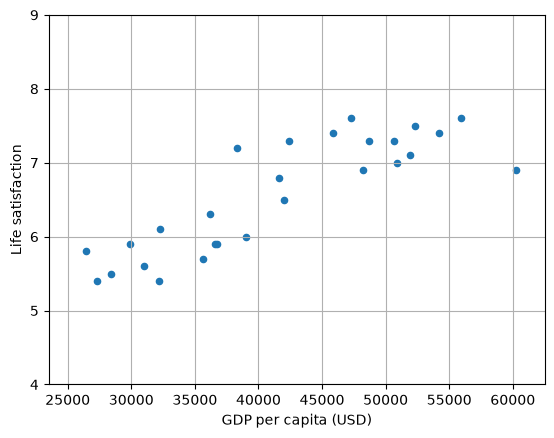

[[10.50457548]]


In [49]:
X = dff[["GDP per capita (USD)"]].values
y = dff[["Life satisfaction"]].values

# Visualize the data
dff.plot(kind='scatter', grid=True,
             x="GDP per capita (USD)", y="Life satisfaction")
plt.axis([23_500, 62_500, 4, 9])
plt.show()

# Select a linear model
model = LinearRegression()

# Train the model
model.fit(X, y)

# Make a prediction for Cyprus
X_new = [[99_655.2]]  # Cyprus' GDP per capita in 2020
print(model.predict(X_new)) # outputs [[6.30165767]]